# Week 3: Baseline Model, TF-IDF + Logistic Regression
**Project:** Claude or Classifier? Cost-Aware Triage of App User Feedback
**Author:** Westin Pals, MSAI-699-B01 Capstone

**Task.** Multi-label classification of English app reviews into three labels: `problem_report`, `feature_request`, `irrelevant` (Mini-BAR dataset, Wei et al., 2023).

**Baseline choice.** A TF-IDF bag of word unigrams and bigrams feeding one logistic regression classifier per label (one-vs-rest). It is the standard, transparent starting point for text classification: fast on a CPU, essentially free to run, and its weights can be read directly. Every later model (fine-tuned DistilBERT, Claude via the Anthropic API, and the cascade) has to beat this number to justify its extra cost.

**Evaluation protocol** (reused for all later models):
1. Fixed, stratified 80/20 train/test split built in `src/data_prep.py` after cleaning and de-duplication.
2. 5-fold cross-validation on the training set for a stable estimate.
3. Held-out test set metrics: per-label precision, recall, F1, plus macro F1 (primary metric because the labels are imbalanced).
4. Cross-app test: train on two apps, test on the third.
5. Runtime and cost per 1,000 reviews.

In [1]:
import json, os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             hamming_loss, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
from data_prep import LABELS, APPS, RANDOM_STATE, load_prepared

RESULTS = os.path.join(ROOT, 'results')
os.makedirs(os.path.join(RESULTS, 'figures'), exist_ok=True)
np.random.seed(RANDOM_STATE)

## 1. Load, clean, and split

In [2]:
df, clean_log = load_prepared(save=True)
print(clean_log)
train, test = df[df.split == 'train'], df[df.split == 'test']
print('train', len(train), '| test', len(test))
df.groupby('split')[LABELS].mean().round(3)

{'rows_raw': 6000, 'unlabeled_fixed': 2, 'still_unlabeled': 0, 'duplicates_removed': 154, 'rows_clean': 5846}
train 4676 | test 1170


,problem_report,feature_request,irrelevant
split,,,
test,0.338,0.196,0.485
train,0.336,0.197,0.485


## 2. Model definition

In [3]:
def build_baseline():
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  lowercase=True, strip_accents='unicode')),
        ('clf', OneVsRestClassifier(LogisticRegression(
            C=1.0, class_weight='balanced', solver='liblinear', max_iter=2000,
            random_state=RANDOM_STATE))),
    ])

def evaluate(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, zero_division=0)
    out = {lab: {'precision': p[i], 'recall': r[i], 'f1': f[i], 'support': int(s[i])}
           for i, lab in enumerate(LABELS)}
    out['macro_f1'] = f1_score(y_true, y_pred, average='macro', zero_division=0)
    out['micro_f1'] = f1_score(y_true, y_pred, average='micro', zero_division=0)
    out['subset_accuracy'] = accuracy_score(y_true, y_pred)
    out['hamming_loss'] = hamming_loss(y_true, y_pred)
    return out

X_train, Y_train = train['text'].values, train[LABELS].values
X_test, Y_test = test['text'].values, test[LABELS].values

## 3. Reference points (no learning)
A model that always predicts the most common value for each label, and one that guesses at random with the training label rates. The baseline has to clear both.

In [4]:
ref = {}
for name, strategy in [('majority', 'most_frequent'), ('random_stratified', 'stratified')]:
    dummy = OneVsRestClassifier(DummyClassifier(strategy=strategy, random_state=RANDOM_STATE))
    dummy.fit(X_train.reshape(-1, 1), Y_train)
    ref[name] = evaluate(Y_test, dummy.predict(X_test.reshape(-1, 1)))
    print(f"{name:18s} macro F1 = {ref[name]['macro_f1']:.3f}")

majority           macro F1 = 0.000
random_stratified  macro F1 = 0.340


## 4. Five-fold cross-validation on the training set

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = []
for k, (tr, va) in enumerate(skf.split(X_train, train['label_combo'])):
    m = build_baseline().fit(X_train[tr], Y_train[tr])
    cv_scores.append(f1_score(Y_train[va], m.predict(X_train[va]), average='macro'))
    print(f'fold {k+1}: macro F1 = {cv_scores[-1]:.3f}')
print(f'CV macro F1 = {np.mean(cv_scores):.3f} +/- {np.std(cv_scores):.3f}')

fold 1: macro F1 = 0.815


fold 2: macro F1 = 0.831


fold 3: macro F1 = 0.836


fold 4: macro F1 = 0.836


fold 5: macro F1 = 0.831
CV macro F1 = 0.830 +/- 0.008


## 5. Train on the full training set and test on the held-out set

In [6]:
model = build_baseline()
t0 = time.perf_counter(); model.fit(X_train, Y_train); train_sec = time.perf_counter() - t0
t0 = time.perf_counter(); Y_pred = model.predict(X_test); infer_sec = time.perf_counter() - t0
test_metrics = evaluate(Y_test, Y_pred)
print(classification_report(Y_test, Y_pred, target_names=LABELS, digits=3, zero_division=0))
print(f"macro F1 {test_metrics['macro_f1']:.3f} | micro F1 {test_metrics['micro_f1']:.3f} | "
      f"subset accuracy {test_metrics['subset_accuracy']:.3f} | hamming loss {test_metrics['hamming_loss']:.3f}")
print(f'train time {train_sec:.2f}s | inference {1000*infer_sec/len(X_test):.3f}s per 1,000 reviews | API cost $0')

                 precision    recall  f1-score   support

 problem_report      0.790     0.896     0.840       395
feature_request      0.611     0.830     0.704       229
     irrelevant      0.930     0.912     0.921       567

      micro avg      0.807     0.891     0.847      1191
      macro avg      0.777     0.879     0.821      1191
   weighted avg      0.822     0.891     0.852      1191
    samples avg      0.830     0.891     0.850      1191

macro F1 0.821 | micro F1 0.847 | subset accuracy 0.761 | hamming loss 0.109
train time 0.33s | inference 0.052s per 1,000 reviews | API cost $0


### Results by app and by review length

In [7]:
rows = []
for app in APPS:
    m = (test['app'] == app).values
    rows.append({'slice': app, 'n': int(m.sum()), 'macro_f1': f1_score(Y_test[m], Y_pred[m], average='macro', zero_division=0)})
short = (test['text'].str.split().str.len() <= 3).values
for name, m in [('<= 3 words', short), ('> 3 words', ~short)]:
    rows.append({'slice': name, 'n': int(m.sum()), 'macro_f1': f1_score(Y_test[m], Y_pred[m], average='macro', zero_division=0)})
slices = pd.DataFrame(rows).round(3); slices

,slice,n,macro_f1
0,Garmin Connect,401,0.809
1,Huawei Health,389,0.804
2,Samsung Health,380,0.828
3,<= 3 words,206,0.665
4,> 3 words,964,0.816


## 6. Cross-app generalization: train on two apps, test on the third

In [8]:
cross = []
for held in APPS:
    tr, te = df[df.app != held], df[df.app == held]
    m = build_baseline().fit(tr['text'].values, tr[LABELS].values)
    pred = m.predict(te['text'].values)
    res = evaluate(te[LABELS].values, pred)
    cross.append({'held_out_app': held, 'n_test': len(te), 'macro_f1': res['macro_f1'],
                  **{f'{l}_f1': res[l]['f1'] for l in LABELS}})
cross = pd.DataFrame(cross).round(3); cross

,held_out_app,n_test,macro_f1,problem_report_f1,feature_request_f1,irrelevant_f1
0,Garmin Connect,2000,0.780,0.861,0.581,0.898
1,Huawei Health,1946,0.788,0.852,0.628,0.883
2,Samsung Health,1900,0.805,0.766,0.735,0.915


## 7. What the model learned: top-weighted n-grams per label

In [9]:
vocab = np.array(model.named_steps['tfidf'].get_feature_names_out())
top = {}
for i, lab in enumerate(LABELS):
    coefs = model.named_steps['clf'].estimators_[i].coef_.ravel()
    top[lab] = list(vocab[np.argsort(coefs)[-12:][::-1]])
pd.DataFrame(top)

,problem_report,feature_request,irrelevant
0,not,add,love
1,update,would,great
2,sync,please,good
3,can,be,best
4,doesn,wish,very
5,fix,why,easy
6,after,option,awesome
7,steps,that,nice
8,connect,could,excellent
9,work,but,easy to


## 8. Error analysis: missed feature requests

In [10]:
fr = LABELS.index('feature_request')
missed = test[(Y_test[:, fr] == 1) & (Y_pred[:, fr] == 0)]
print(f'missed feature requests: {len(missed)} of {int(Y_test[:, fr].sum())}')
pd.set_option('display.max_colwidth', 160)
missed[['app', 'text']].head(8)

missed feature requests: 39 of 229


,app,text
250,Garmin Connect,Not very accurate will not sink - MyFitnessPal would not buy again. Mobile app error all the time.
376,Garmin Connect,I really enjoy garmin and the options that it gives me. The only thing I not a fan of it keeps telling me to move after I get back from some activitie
759,Garmin Connect,Can't login Connect IQ store with Google account. It's hilarious considering the Connect app suggests you to use itself for ease of connection to IQ store.
978,Garmin Connect,A very handy app but occasionally it's slow to connect to my device. I recently changed from a Nokia mobile phone which is not fully supported to an androi...
1352,Garmin Connect,Needs smart alarm
1470,Garmin Connect,"My Garmin watch and the Garmin connect app is very easy to setup and understand, I found it a little slow to log certain workouts such as strength training ..."
1494,Garmin Connect,Getting better and faster ... Keep it up. Adding 7 minutes workout kind of activities with sample will be great feature.
1497,Garmin Connect,"Pretty comprehensive with it's data. The data screens are all well presented and easy to read. The app itself can be a little odd to navigate, but once you'..."


## 9. Save results for later comparison

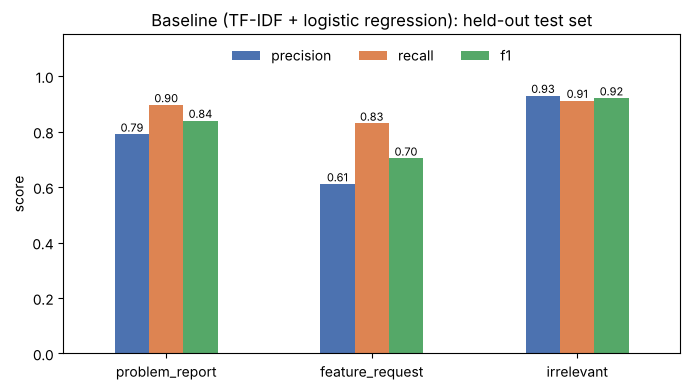

saved


In [11]:
per = pd.DataFrame({l: test_metrics[l] for l in LABELS}).T[['precision', 'recall', 'f1']]
ax = per.plot.bar(figsize=(7, 4), rot=0, ylim=(0, 1.15), color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_title('Baseline (TF-IDF + logistic regression): held-out test set')
ax.set_ylabel('score'); ax.legend(loc='upper center', ncol=3, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'figures', 'baseline_test_metrics.png'), dpi=150); plt.show()

summary = {
    'model': 'tfidf_word_1-2gram + one_vs_rest_logreg (class_weight=balanced, C=1.0)',
    'cleaning': clean_log,
    'n_train': len(train), 'n_test': len(test),
    'reference': {k: v['macro_f1'] for k, v in ref.items()},
    'cv_macro_f1_mean': float(np.mean(cv_scores)), 'cv_macro_f1_std': float(np.std(cv_scores)),
    'test': test_metrics,
    'cross_app': cross.to_dict(orient='records'),
    'slices': slices.to_dict(orient='records'),
    'train_seconds': train_sec, 'inference_seconds_per_1000': 1000 * infer_sec / len(X_test),
    'api_cost_usd_per_1000': 0.0,
}
with open(os.path.join(RESULTS, 'baseline_metrics.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=float)
pred_df = test[['review_id', 'app', 'text'] + LABELS].copy()
for i, l in enumerate(LABELS): pred_df[f'pred_{l}'] = Y_pred[:, i]
pred_df.to_csv(os.path.join(RESULTS, 'baseline_test_predictions.csv'), index=False)
print('saved')